# Problem 0 (3 pts)

### Connected graph

* First of all create PageRank matrix $A$ that corresponds to the following graph: <img src="data/graph1.png" width='200'> Make sure that your matrix is stochastic. What is the largest eigenvalue of this matrix?


* Implement power method and plot relative errors ${|\lambda_{k+1} - 1|}$ and $\frac{\|x_{k+1} - x_{k}\|}{\|x_{k+1}\|}$ (since you have no information about $x$) as a function of $k$, where $k$ is the interation number. <font color='red'>DO NOT FORGET TO USE LOGARITHMIC SCALE!</font>

### Disconneted graph: damping factor importance

* Create PageRank matrix $A$ that corresponds to the following graph: <img src="data/graph2.png" width='200'>

* Run the power method and plot relative errors ${|\lambda_{k+1} - 1|}$  and $\frac{\|x_{k+1} - x_{k}\|}{\|x_{k+1}\|}$ as a function of $k$. Why do you observe the absense of convergence? <br> **Hint:** think about the multiplicity of $\lambda=1$

In order to avoid this problem Larry Page and Sergey Brin proposed to use the following regularization technique:
$$
A_d = dA + \frac{1-d}{N} \begin{pmatrix} 1 & \dots & 1 \\ \vdots & & \vdots \\ 1 & \dots & 1 \end{pmatrix},
$$
where $d$ is small parameter (typically $d=0.85$), which is called **damping factor**, $A$ is of size $N\times N$. Now $A_d$ is the matrix with multiplicity of the largest eigenvalue equal to 1. 
Recall that computing the eigenvector of the PageRank matrix which corresponds to the largest eigenvalue has the following interpretation: consider a person who stays in a random node of the graph (i.e. opens a random web page); at each step he follows one of the outcoming edges uniformly at random (i.e. opens one of the links). So the guy randomly walks through the graph and the eigenvector we are looking for is exactly his stationary distribution — for each node it tells you the probability of visiting this particular node. Therefore if the guy has started from a part of a graph which is not connected with the other part, he will never get there.  In the regularized model the person at each step follows one of the outcoming links with probability $d$ OR visits a random node from the whole graph with probability $(1-d)$.

* Now run the power method with $A_d$ and plot errors as a function of iteration for different $d$.

### Simple English Wiki

Let us now find the most significant articles on the simple english Wikipedia according to the PageRank model. We provide you with the adjecency matrix of the simple Wikipedia articles (file `data/simple_wiki_matrix.mat`, matrix can be acessed by the key `'W'`) and the dictionary that maps article id to its name on Wikipedia (file `data/simple_wiki_dict.pickle`).

* Normalize each column of the adjecency matrix to get a matrix from the PageRank model. Check that the obtained matrix is stochastic.

* Plot relative errors ${|\lambda_{k+1} - 1|}$  and $\frac{\|x_{k+1} - x_{k}\|}{\|x_{k+1}\|}$ as a function of $k$ for different $d$. **Note** that your matrix contains a lot of zeros and is stored in the sparse format. Hence `np.dot(A, x)` will not work. However, sparse matrices has method `.dot()`, so `A.dot(x)` works fine.

* Print names of top-5 articles when $d=0.85$.

# Problem 1 (3 pts)

Consider the following two models:
### Personalized PageRank
This is the same model as standard PageRank, but every node has a certain "teleport" weight $t_i$. It models the preference of the user to restart the browsing with certain pages more than others (the probability of restarting at node $i$ is thus not necessarily uniform and is instead proportional to $\frac{t_i}{\sum t_j}$).
### Friedkin-Johnsen Opinion Dynamics
$N$ agents are dynamically forming their opinions on a certain subject. Every agent has an innate level of conviction (prejudice) $s_i$ and a susceptibility coefficient $\lambda_i$ determining how much this agent is influenced by the opinions of others. Let $W$ be a given row-stochastic matrix of opinion weighting (determining the weighted average every agent applies to the opinions of others) and $\Lambda = diag\{\lambda_1, \ldots, \lambda_N\}$, then the dynamics of the opinion forming is described as
$$x_{t+1} = \Lambda W x_t + (I - \Lambda)s$$
with the steady state
$$(I - \Lambda W)x = (I - \Lambda)s.$$

## Task 1
Describe how Personalized PageRank can be considered a special case of the FJ model.

*your explanation here*

## Task 2
We shall now use the FJ model as a part of a more complex dynamics that we'll call *opinion crystallization*. Suppose that after the system reaches a stationary state $x$, it becomes the new baseline $s$. However, agent 1 is designated an *opinion leader* of the positive party and sticks to their original innate opinion $s^*_1$; with time, their susceptibility to opinions of others is decaying towards zero. Positive party's members pay significant attention to the leader.

*You can model different other political situations by altering the initialization of $W$ and sweeping $\lambda$ and $s$.*

Below is a brute-force implementation of the parameterized crystallization model assuming a bipartisan interaction matrix $W$ and initial convictions being polarized across the two parties.

Your task will be to avoid the costly $\Omega(n^3)$ matrix inversion at each step by observing that the inverted matrix only differs in a rank-one term (i.e., the difference between subsequent matrices to be inverted can be represented as $u^T v$ for some vectors $u$ and $v$) and applying the [Sherman-Morrison formula](https://en.wikipedia.org/wiki/Sherman%E2%80%93Morrison_formula). Please keep the brute-force implementation and compare the results numerically. What is the time complexity of your approach? Pick a larger $N$ and measure the practical speedup.

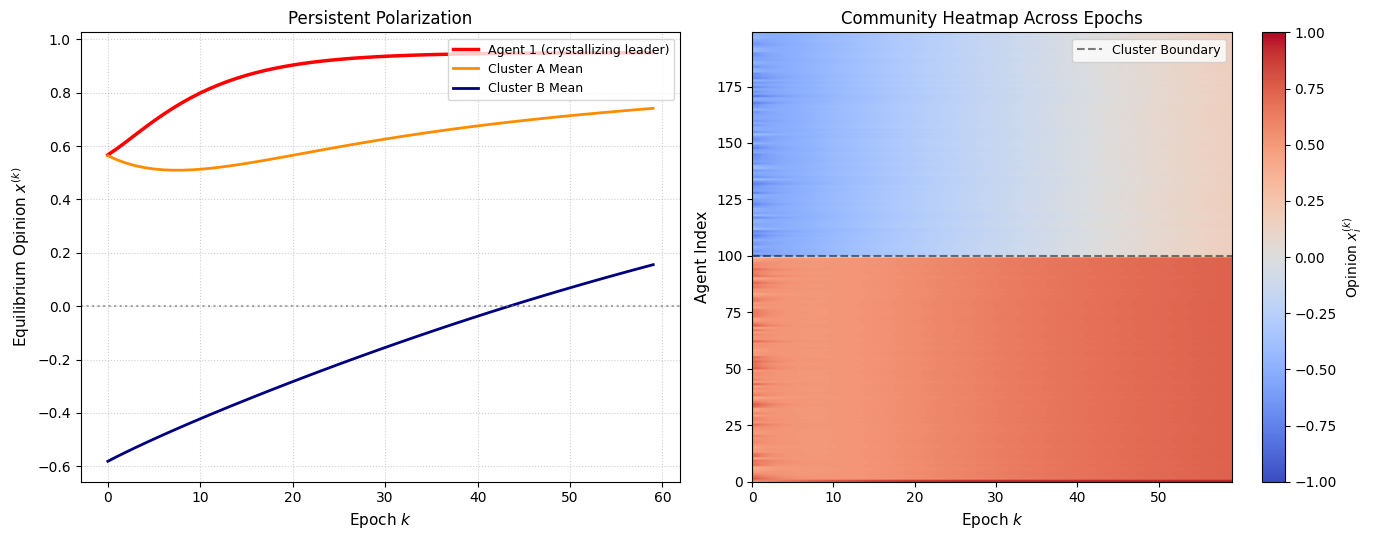

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Setup Polarized Network & Parameters
# -------------------------------------------------------------
np.random.seed(42)
n = 200
assert n % 2 == 0, "For simplicity, parties are assumed to be of the same size"
half = n // 2
T_epochs = 60

# Split into two clusters: 0..half (positive), half..n (negative)
s_0 = np.zeros((n, 1))
s_0[:half] = np.random.uniform(0.3, 0.9, size=(half, 1))
s_0[half:] = np.random.uniform(-0.9, -0.3, size=(half, 1))

# Agent 1 starts as an extreme positive leader
sticky_s1 = 0.95  # Agent 1 retains this core ideological anchor
s_0[0, 0] = sticky_s1

# Susceptibilities: base values for all agents, decay schedule for Agent 1
lambdas_base = np.random.uniform(0.3, 0.7, size=n)
gamma_decay = 0.90
lambda_1_history = [0.95 * (gamma_decay ** k) for k in range(T_epochs)]

# -------------------------------------------------------------
# 2. Block-Structured Interaction Matrix (Echo Chambers)
# -------------------------------------------------------------
raw_W = np.zeros((n, n))

# Strong intra-cluster ties
raw_W[:half, :half] = np.random.uniform(0.1, 0.5, size=(half, half))
raw_W[half:, half:] = np.random.uniform(0.1, 0.5, size=(half, half))

# Weak cross-cluster bridge ties
raw_W[:half, half:] = np.random.uniform(0.001, 0.01, size=(half, half))
raw_W[half:, :half] = np.random.uniform(0.001, 0.01, size=(half, half))

raw_W[1:half, 0] = 2.0  # Leader's party members pay heavy direct attention to leader (Agent 1)

np.fill_diagonal(raw_W, 0.0)
W = raw_W / raw_W.sum(axis=1, keepdims=True)  # Row stochasticity

I = np.eye(n)

# -------------------------------------------------------------
# 3. Brute-force simulation: Direct inversion on each epoch
# -------------------------------------------------------------
s_current = s_0.copy()
opinion_history = np.zeros((n, T_epochs))

for k in range(T_epochs):
    # Update Agent 1's susceptibility for the current epoch
    l1 = lambda_1_history[k]
    lambdas = lambdas_base.copy()
    lambdas[0] = l1
    Lambda = np.diag(lambdas)
    
    # Enforce sticky conviction for Agent 1
    s_current[0, 0] = sticky_s1
    
    # Assemble Friedkin-Johnsen linear system: (I - Lambda * W) x = (I - Lambda) s
    A = I - Lambda @ W
    b = (I - Lambda) @ s_current
    
    # Brute-force solve via explicit matrix inversion: O(n^3) per epoch
    A_inv = np.linalg.inv(A)
    x_k = A_inv @ b
    
    opinion_history[:, k] = x_k.ravel()
    
    # Next iteration update: peers assimilate previous consensus (Agent 1 will have it reset)
    s_current = x_k.copy()

# -------------------------------------------------------------
# 4. Visualization
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
epochs = np.arange(T_epochs)

# Plot 1: Representative Trajectories
ax1.plot(epochs, opinion_history[0, :], "r-", linewidth=2.5, label="Agent 1 (crystallizing leader)")
ax1.plot(epochs, np.mean(opinion_history[:half, :], axis=0), "darkorange", linewidth=2, label="Cluster A Mean")
ax1.plot(epochs, np.mean(opinion_history[half:, :], axis=0), "navy", linewidth=2, label="Cluster B Mean")

ax1.axhline(0, color="gray", linestyle=":", alpha=0.7)
ax1.set_xlabel("Epoch $k$", fontsize=11)
ax1.set_ylabel("Equilibrium Opinion $x^{(k)}$", fontsize=11)
ax1.set_title("Persistent Polarization", fontsize=12)
ax1.legend(loc="upper right", fontsize=9)
ax1.grid(True, linestyle=":", alpha=0.6)

# Plot 2: Heatmap showing distinct cluster evolution
im = ax2.imshow(
    opinion_history,
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
    extent=[0, T_epochs - 1, 0, n-1],
    vmin=-1.0,
    vmax=1.0
)
plt.colorbar(im, ax=ax2, label=r"Opinion $x_i^{(k)}$")
ax2.axhline(100, color="black", linestyle="--", alpha=0.5, label="Cluster Boundary")
ax2.set_title("Community Heatmap Across Epochs", fontsize=12)
ax2.set_xlabel("Epoch $k$", fontsize=11)
ax2.set_ylabel("Agent Index", fontsize=11)
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

*please don't forget to include your report*

# Problem 2 (2 pts)

<img src='https://upload.wikimedia.org/wikipedia/commons/6/67/Eigenfaces.png?20051201171555' width=250>

The aim of this task is to build a face classifier. There are 40 persons in the database. Every person is represented by 10 photos with slightly different facial expression. 
- The database of faces is attached: `data/orl_faces.zip`

- Create training sample:

  Import first 9 images for each face ($9\times 40$ images). Represent these pictures as a matrix $F$ with $9\times 40$ columns, where each column is a reshaped 2D picture. Note: use `np.reshape` to reshape matrix into column
  
  
- Calculate and plot mean face. Subtract it from each column of the matrix $F$

- Calculate SVD decomposition of the shifted matrix F and truncate the obtained representaition: $F_r = U_r S_r V_r^T$. 

 Here $U_r$ is a matrix with $r$ columns - basis set in a space of faces. $W_r = S_r V_r^T$ is a matrix of coefficients in the basis $U_r$. Note that now every image is represented as a small number of coefficients in the basis $U_r$.
 
 
- Plot vectors in $U_r$ using subplots. Make sure that you get face-like images. Now you know what eigenfaces are =)

- Import testing set which is the rest of photos. Find their coefficients in the basis $U_r$. 

- Compare the obtained vectors of coefficients to vectors in $W_r$ using cosine similarity and classify testing faces. As an output give indices of faces that were misclassified when $r=5$.

## Problem 3 (2 pts) - The case for symplectic integrators

In the lecture, we mentioned that the special class of integrators called *symplectic* preserves certain physical invariants of the modeled system over time. Consider the following *symplectic (semi-implicit) Euler* method for a system of equations involving both position $x$ and velocity $v$: update the velocity using the Euler step, and subsequently use the updated velocity in the position update (proving that it indeed preserves the Hamiltonian, i.e. cumulative energy, of the system, is left outside the scope).

In addition to the explicit Euler method implementation provided, implement the symplectic Euler method and the 4-th order Runge-Kutta and observe how they represent the trajectories of the movement of the pendulum system presented.

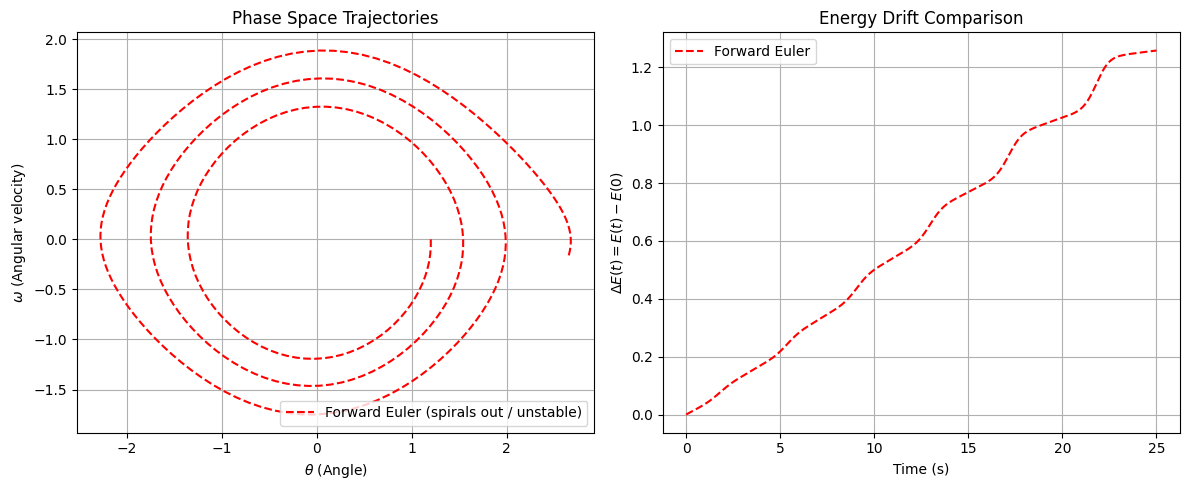

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# System: dtheta/dt = omega, domega/dt = -sin(theta)
def derivatives(theta, omega):
    return omega, -np.sin(theta)

def energy(theta, omega):
    return 0.5 * omega**2 - np.cos(theta)

# Simulation parameters
dt = 0.08       # Moderately coarse step size to expose solver behavior
t_max = 25.0
steps = int(t_max / dt)
t = np.linspace(0, t_max, steps)

theta0 = 1.2    # Initial angle (radians)
omega0 = 0.0    # Initial angular velocity

# 1. Forward Euler
th_fe = np.zeros(steps)
om_fe = np.zeros(steps)
th_fe[0], om_fe[0] = theta0, omega0
for i in range(steps - 1):
    d_th, d_om = derivatives(th_fe[i], om_fe[i])
    th_fe[i+1] = th_fe[i] + dt * d_th
    om_fe[i+1] = om_fe[i] + dt * d_om

# 2. Symplectic (Semi-Implicit) Euler
th_se = np.zeros(steps)
om_se = np.zeros(steps)
th_se[0], om_se[0] = theta0, omega0
for i in range(steps - 1):
    # TODO: your implementation here
    pass

# 3. Runge-Kutta 4 (RK4)
th_rk = np.zeros(steps)
om_rk = np.zeros(steps)
th_rk[0], om_rk[0] = theta0, omega0
for i in range(steps - 1):
    # TODO: your implementation here
    pass

# Plotting (TODO: uncomment the plots for your implementations)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: Phase space (theta vs omega)
ax1.plot(th_fe, om_fe, 'r--', label='Forward Euler (spirals out / unstable)')
# ax1.plot(th_se, om_se, 'g-',  label='Symplectic Euler (bounded orbit)')
# ax1.plot(th_rk, om_rk, 'b-',  label='RK4 (high precision)')
ax1.set_xlabel(r'$\theta$ (Angle)')
ax1.set_ylabel(r'$\omega$ (Angular velocity)')
ax1.set_title('Phase Space Trajectories')
ax1.grid(True)
ax1.legend()

# Right: Energy drift over time
e0 = energy(theta0, omega0)
ax2.plot(t, energy(th_fe, om_fe) - e0, 'r--', label='Forward Euler')
# ax2.plot(t, energy(th_se, om_se) - e0, 'g-',  label='Symplectic Euler')
# ax2.plot(t, energy(th_rk, om_rk) - e0, 'b-',  label='RK4')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel(r'$\Delta E(t) = E(t) - E(0)$')
ax2.set_title('Energy Drift Comparison')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

*please don't forget to include your report*